<a href="https://colab.research.google.com/github/omarelmalak/csc490-group2/blob/omar-owl-pipeline-frame-extract/OWL_Match_Labeler_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logo labeler for one match (OWLv2, Colab)

**End-to-end for one match:** match MP4 → close-up frames (grass heuristic) → OWLv2 logo boxes from your example crops → YOLO labels + annotated frames.

Finds sponsor logos (Riyadh Air, Hyundai, Nike, ...) in the **close-up** frames of one match and writes YOLO labels,
using a few example boxes you give it from that same match. All brands are detected in one pass.

### What you upload (one folder in your Google Drive)
```
my_match/
  <match>.mp4      full match footage (or set VIDEO_PATH to any Drive/Colab path)
  examples.txt     your example boxes (format below)
  # optional if you already extracted frames:
  # close_ups/ or frames/ or close_ups.zip
```

Step 3b runs the same close-up heuristic as `groundingdino/data_collection/frame_extractor.py`
(`green_ratio > 0.40` → wide; else → close-up), writes `close_ups/` + `wide_shots/`, and zips
`close_ups.zip` into the Colab workspace (`/content/close_ups.zip`) and your match folder.
OWLv2 then runs on those close-ups.

### `examples.txt`
One example per line: **brand, frame, box** (pixel corners `x1,y1,x2,y2` in that frame). Lines starting with `#` are ignored.
```
riyadh_air  frame_00000.jpg  130,216,166,262
hyundai     frame_00870.jpg  456,230,492,252
nike        frame_00754.jpg  404,186,426,203
negative    frame_00199.jpg  527,28,543,44      # things that must NOT be labeled (crests, league badge, numbers...)
```
**Tips for good examples** (these matter more than anything else):
- **3-10 per brand**, covering each kit (home / away / keeper), different angles and some blur.
- **Box only the logo, tightly.** Background inside the box becomes part of what it searches for.
- Add `negative` lines for lookalikes it gets wrong (club crests, kit-maker logos, the league badge, shirt numbers).
- Each brand's examples automatically count as negatives for the other brands.

### Run
1. **Runtime → Change runtime type → T4 GPU**
2. Set `MATCH_DIR` + `VIDEO_PATH` (and `CLASSES` if needed) in step 1, then run top to bottom.
3. Step 3b builds `close_ups.zip` from the MP4 (skip if you already have `close_ups/` / `frames/`).
4. Check example previews (step 5) and boxes (step 8) — adjust cutoffs in step 9 if needed.

Results land in `MATCH_DIR/owl_output/`: `labels/` (YOLO), `annotated/` (frames with boxes),
`candidates/`, `summary.csv`, and `yolo_dataset/` from step 10.
If Colab disconnects, re-run — step 7 continues where it stopped.

In [1]:
import gspread
from google.colab import auth
import google.auth

# Authenticate user
auth.authenticate_user()

# Get credentials and initialize gspread client
creds, _ = google.auth.default()
gc = gspread.authorize(creds)
print("Google Sheets API client successfully authorized!")

Google Sheets API client successfully authorized!


In [58]:
# 1. Settings - edit these
# Base folder on your Google Drive containing all your matches
BASE_MATCHES_DIR = "/content/drive/MyDrive/matches"

# The specific subfolder inside the matches directory for this game
# Make sure it follows the structure 'team1_vs_team2'
CURRENT_MATCH_FOLDER = "real_madrid_vs_atletico_madrid"

MATCH_DIR = f"{BASE_MATCHES_DIR}/{CURRENT_MATCH_FOLDER}"    # folder with examples.txt (+ video or existing frames)

# Match footage for close-up extraction (step 3b). Absolute path, or a filename under MATCH_DIR.
# Set to None to skip extraction and use existing close_ups/ / frames/ / close_ups.zip instead.
VIDEO_PATH = "match.mp4"          # e.g. "athletico_real_2023.mp4" or "/content/drive/MyDrive/.../match.mp4"
INTERVAL_SECONDS = 1.0             # 1 frame per second
GREEN_RATIO_WIDE = 0.40           # green_ratio > this → wide_shots; else → close_ups
START_MINUTES = 0.0
DURATION_MINUTES = None           # None = entire video; or e.g. 15 for a quick test
FORCE_REEXTRACT = False           # True = rebuild close_ups even if the folder already exists

# --- Dynamic Class Lookup from Google Sheets ---
import pandas as pd
import gspread
from google.colab import auth
import google.auth
import unicodedata

TARGET_SHEET_URL = 'https://docs.google.com/spreadsheets/d/1aFTflmiIrB43JPFam8_wSHL7xt5BLDmXt1YirBrDbgg/edit?usp=sharing'
CLASSES = []

def clean_text(text):
    """Normalize accents (e.g. Atlético -> Atletico) and lowercase/strip text."""
    if not isinstance(text, str):
        return ""
    normalized = unicodedata.normalize('NFKD', text)
    ascii_bytes = normalized.encode('ASCII', 'ignore')
    return ascii_bytes.decode('utf-8').strip().lower()

try:
    # Authenticate and load spreadsheet data
    auth.authenticate_user()
    creds, _ = google.auth.default()
    gc = gspread.authorize(creds)
    sh = gc.open_by_url(TARGET_SHEET_URL)
    worksheet = sh.get_worksheet(0)

    # Fetch all values to manually build headers safely
    raw_rows = worksheet.get_all_values()
    if raw_rows:
        # Find the header row containing 'kit manufacturer' or 'main sponsor'
        header_idx = 0
        for idx, row in enumerate(raw_rows):
            row_lower = [str(cell).strip().lower() for cell in row]
            if 'kit manufacturer' in row_lower or 'main sponsor' in row_lower:
                header_idx = idx
                break

        raw_headers = raw_rows[header_idx]
        # Handle empty/blank or duplicate columns robustly
        headers = [h.strip().lower() if h.strip() != '' else f'col_{i}' for i, h in enumerate(raw_headers)]
        seen = {}
        final_headers = []
        for h in headers:
            if h in seen:
                seen[h] += 1
                final_headers.append(f"{h}_{seen[h]}")
            else:
                seen[h] = 0
                final_headers.append(h)

        sponsor_df = pd.DataFrame(raw_rows[header_idx+1:], columns=final_headers)

        # Parse home and away teams from folder name
        folder_clean = CURRENT_MATCH_FOLDER.replace('_', ' ').lower()
        if ' vs ' in folder_clean:
            teams = [t.strip() for t in folder_clean.split(' vs ')]
        else:
            teams = [folder_clean]

        sponsors = []
        # Identify the team column dynamically (usually the first main text column or 'team')
        team_col = None
        for col in sponsor_df.columns:
            if 'team' in col:
                team_col = col
                break
        if not team_col:
            team_col = sponsor_df.columns[0]

        # List of candidate columns where sponsors are specified
        sponsor_cols_keywords = [
            'kit manufacturer', 'main sponsor',
            'secondary sponsor 1', 'secondary sponsor 2',
            'secondary sponsor 3', 'secondary sponsor 4',
            'secondary sponsor 5'
        ]

        # Find the actual dataframe columns matching our sponsor keywords
        actual_sponsor_cols = []
        for col in sponsor_df.columns:
            for kw in sponsor_cols_keywords:
                if kw in col:
                    actual_sponsor_cols.append(col)
                    break

        for team_query in teams:
            cleaned_query = clean_text(team_query)
            # Run an element-wise row match using clean_text logic on the Team column
            match_rows = sponsor_df[sponsor_df[team_col].apply(clean_text) == cleaned_query]
            if not match_rows.empty:
                row_series = match_rows.iloc[0]
                for col in actual_sponsor_cols:
                    val = str(row_series[col]).strip()
                    if val and val != '-' and val != '' and val.lower() != 'none':
                        # If there are multiple comma-separated values in one cell, handle them
                        for item in val.split(','):
                            # Lowercase and replace spaces with underscores from the beginning!
                            clean_item = item.strip().lower().replace(' ', '_')
                            if clean_item and clean_item != '-':
                                sponsors.append(clean_item)

        # Unique sorted active sponsors for the classes array
        CLASSES = sorted(list(set(sponsors)))
        print(f"Dynamically loaded pre-normalized CLASSES from sheet for teams {teams}: {CLASSES}")
except Exception as e:
    print(f"Could not dynamically load CLASSES: {e}. Using fallback classes.")
    CLASSES = ["riyadh_air", "hyundai", "nike", "adidas"]

DEFAULT_CUTOFF = 0.93   # a box needs at least this score
CUTOFFS = {}            # per-brand overrides, e.g. {"riyadh_air": 0.92}
TILES = 2               # 2 = also scan 4 enlarged tiles per frame; 1 = whole frame only
ONLY_FRAMES = None      # quick test on a few frames; None = all frames

Dynamically loaded pre-normalized CLASSES from sheet for teams ['real madrid', 'atletico madrid']: ['adidas', 'emirates', 'hyundai', 'nike', 'ria_money_transfer', 'riyadh_air']


In [8]:
# 2. GPU check (should print a Tesla T4; "no GPU" means it will be very slow)
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU - Runtime > Change runtime type > T4 GPU")

GPU: Tesla T4


In [9]:
# 3. Connect Google Drive and resolve the match folder
import os, shutil, zipfile
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:          # running in Jupyter on your own computer
    IN_COLAB = False

MATCH = Path(MATCH_DIR)
MATCH.mkdir(parents=True, exist_ok=True)
EXAMPLES_TXT = MATCH / "examples.txt"
OUT = MATCH / "owl_output"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
VIDEO_EXTS = {".mp4", ".mov", ".mkv", ".avi", ".webm"}

def resolve_video_path():
    """VIDEO_PATH may be absolute, relative to MATCH, or None."""
    if not VIDEO_PATH:
        # auto-pick a single video sitting in MATCH_DIR
        vids = sorted(p for p in MATCH.iterdir() if p.suffix.lower() in VIDEO_EXTS)
        if len(vids) == 1:
            return vids[0]
        return None
    p = Path(VIDEO_PATH)
    if p.is_file():
        return p
    cand = MATCH / VIDEO_PATH
    if cand.is_file():
        return cand
    raise FileNotFoundError(f"VIDEO_PATH not found: {VIDEO_PATH} (also looked under {MATCH})")

VIDEO_FILE = resolve_video_path()
print(f"match folder: {MATCH}")
print(f"video: {VIDEO_FILE if VIDEO_FILE else '(none — will use existing close_ups/frames/zip)'}")
print(f"examples.txt present: {EXAMPLES_TXT.is_file()}")

Mounted at /content/drive
match folder: /content/drive/MyDrive/matches/real_madrid_vs_atletico_madrid
video: /content/drive/MyDrive/matches/real_madrid_vs_atletico_madrid/match.mp4
examples.txt present: False


In [10]:
#@title 3b. Extract close-ups from match video (grass heuristic) → close_ups.zip
# Same rule as groundingdino/data_collection/frame_extractor.py:
#   green_ratio > GREEN_RATIO_WIDE → wide_shots/; else → close_ups/
# Writes MATCH/close_ups/, MATCH/close_ups.zip, and /content/close_ups.zip (Colab).

import cv2
import numpy as np

def time_filename(frame_idx: int, fps: float) -> str:
    total_seconds = int(frame_idx / fps)
    rem = int(frame_idx % max(fps, 1.0))
    return f"frame_{total_seconds:05d}s_{rem:02d}.jpg"

def extract_close_ups(
    video_path: Path,
    out_root: Path,
    interval_seconds: float = 1.0,
    green_ratio_wide: float = 0.40,
    start_minutes: float = 0.0,
    duration_minutes=None,
):
    close_dir = out_root / "close_ups"
    close_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Failed to open video: {video_path}")

    video_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    total_min = total_frames / (video_fps * 60.0)
    dur = float(duration_minutes) if duration_minutes is not None else total_min

    start_frame = int(start_minutes * 60 * video_fps)
    end_frame = min(int((start_minutes + dur) * 60 * video_fps), total_frames)
    frame_step = max(1, int(round(interval_seconds * video_fps)))

    print(f"Video: {video_path}")
    print(f"FPS={video_fps:.2f}  duration={total_min:.1f} min")
    print(f"Window: {start_minutes:.1f} → {start_minutes + dur:.1f} min | every {interval_seconds}s")
    print(f"Heuristic: green_ratio > {green_ratio_wide} → wide (skipped), else close_ups (saved)")

    lower_green = np.array([35, 40, 40])
    upper_green = np.array([85, 255, 255])
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
    idx, n_close, n_wide = start_frame, 0, 0

    while idx < end_frame:
        ret, frame = cap.read()
        if not ret:
            break
        if (idx - start_frame) % frame_step == 0:
            hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
            mask = cv2.inRange(hsv, lower_green, upper_green)
            green_ratio = cv2.countNonZero(mask) / float(frame.shape[0] * frame.shape[1])
            name = time_filename(idx, video_fps)
            if green_ratio > green_ratio_wide:
                n_wide += 1
            else:
                cv2.imwrite(str(close_dir / name), frame)
                n_close += 1
            if (n_close + n_wide) % 100 == 0:
                print(f"  processed {n_close + n_wide} (saved close={n_close}, skipped wide={n_wide}) last={name}")
        idx += 1
    cap.release()
    print(f"Done. saved close_ups={n_close} | skipped wide={n_wide} → {out_root}")
    return close_dir, n_close, n_wide

def zip_close_ups(close_dir: Path, zip_paths):
    files = sorted(p for p in close_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS)
    if not files:
        raise RuntimeError(f"No images in {close_dir} to zip")
    for zp in zip_paths:
        zp = Path(zp)
        zp.parent.mkdir(parents=True, exist_ok=True)
        if zp.exists():
            zp.unlink()
        with zipfile.ZipFile(zp, "w", compression=zipfile.ZIP_STORED) as zf:
            for p in files:
                zf.write(p, arcname=f"close_ups/{p.name}")
        print(f"zipped {len(files)} close-ups → {zp}")

CLOSE_DIR = MATCH / "close_ups"
CLOSE_ZIP_MATCH = MATCH / "close_ups.zip"
CLOSE_ZIP_CONTENT = Path("/content/close_ups.zip")

already = CLOSE_DIR.is_dir() and any(CLOSE_DIR.glob("*.jpg"))
if VIDEO_FILE is None:
    print("No VIDEO_PATH — skipping extraction (use existing close_ups/frames/zip in the next cell).")
elif already and not FORCE_REEXTRACT:
    print(f"close_ups/ already has frames at {CLOSE_DIR} — skipping extract (set FORCE_REEXTRACT=True to rebuild).")
    zip_close_ups(CLOSE_DIR, [CLOSE_ZIP_MATCH] + ([CLOSE_ZIP_CONTENT] if IN_COLAB else []))
else:
    if FORCE_REEXTRACT and CLOSE_DIR.exists():
        shutil.rmtree(CLOSE_DIR)
    CLOSE_DIR, n_close, n_wide = extract_close_ups(
        VIDEO_FILE,
        MATCH,
        interval_seconds=INTERVAL_SECONDS,
        green_ratio_wide=GREEN_RATIO_WIDE,
        start_minutes=START_MINUTES,
        duration_minutes=DURATION_MINUTES,
    )
    zip_close_ups(CLOSE_DIR, [CLOSE_ZIP_MATCH] + ([CLOSE_ZIP_CONTENT] if IN_COLAB else []))
    print(f"Colab workspace zip: {CLOSE_ZIP_CONTENT if IN_COLAB else '(n/a)'}")

Video: /content/drive/MyDrive/matches/real_madrid_vs_atletico_madrid/match.mp4
FPS=25.00  duration=110.3 min
Window: 0.0 → 110.3 min | every 1.0s
Heuristic: green_ratio > 0.4 → wide_shots, else close_ups
  saved 100 (close=100, wide=0) last=frame_00099s_00.jpg
  saved 200 (close=181, wide=19) last=frame_00199s_00.jpg
  saved 300 (close=250, wide=50) last=frame_00299s_00.jpg
  saved 400 (close=289, wide=111) last=frame_00399s_00.jpg
  saved 500 (close=300, wide=200) last=frame_00499s_00.jpg
  saved 600 (close=341, wide=259) last=frame_00599s_00.jpg
  saved 700 (close=365, wide=335) last=frame_00699s_00.jpg
  saved 800 (close=371, wide=429) last=frame_00799s_00.jpg
  saved 900 (close=385, wide=515) last=frame_00899s_00.jpg
  saved 1000 (close=415, wide=585) last=frame_00999s_00.jpg
  saved 1100 (close=425, wide=675) last=frame_01099s_00.jpg
  saved 1200 (close=428, wide=772) last=frame_01199s_00.jpg
  saved 1300 (close=459, wide=841) last=frame_01299s_00.jpg
  saved 1400 (close=464, wide

In [64]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from PIL import Image
import json
from pathlib import Path
import os
from google.colab import output

# Register callback to receive clicks from Javascript
class InteractiveSponsorAnnotator:
    def __init__(self, frames_dir, output_file, classes_list):
        self.frames_dir = Path(frames_dir)
        self.output_file = Path(output_file)
        # Normalize all active sponsors to lowercase with underscores to avoid space-splitting errors
        self.active_sponsors = sorted(list({c.strip().lower().replace(' ', '_') for c in classes_list})) + ['negative']
        self.frame_paths = sorted([p for p in self.frames_dir.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}])
        self.current_idx = 0
        self.clicks = []
        self.saved_boxes = self.load_existing_boxes()

        # Standard controls
        self.brand_dropdown = widgets.Dropdown(options=self.active_sponsors, description='Brand:')
        self.btn_prev = widgets.Button(description='◀ Prev')
        self.btn_next = widgets.Button(description='Next ▶')
        self.btn_skip = widgets.Button(description='Skip Frame', button_style='warning')
        self.btn_save = widgets.Button(description='Save Box', button_style='success')
        self.btn_clear = widgets.Button(description='Clear Box')

        # Hidden backend coordinate inputs kept for saving logic sync
        self.coord_x1 = widgets.IntText(value=0, description='x1:')
        self.coord_y1 = widgets.IntText(value=0, description='y1:')
        self.coord_x2 = widgets.IntText(value=0, description='x2:')
        self.coord_y2 = widgets.IntText(value=0, description='y2:')

        self.status_label = widgets.Label(value='Click two corners on the image below to automatically capture coordinates!')
        self.counts_disp = widgets.HTML(value='')
        self.canvas_disp = widgets.Output()

        self.btn_prev.on_click(self.prev_frame)
        self.btn_next.on_click(self.next_frame)
        self.btn_skip.on_click(self.skip_frame)
        self.btn_save.on_click(self.save_box)
        self.btn_clear.on_click(self.clear_clicks)

        # Setup Google Colab channel communication
        output.register_callback('notebook.update_coords', self.js_callback_update_coords)

        self.update_counts()
        self.show_frame()

    def load_existing_boxes(self):
        boxes = []
        if self.output_file.exists():
            for line in self.output_file.read_text().splitlines():
                if line.strip() and not line.startswith('#'):
                    parts = line.split()
                    if len(parts) >= 3:
                        # Support brands with spaces (e.g. ['riyadh', 'air', 'frame_000.jpg', '1,2,3,4'])
                        # The box is always the last token, and the frame file name is second to last
                        box_str = parts[-1]
                        frame_str = parts[-2]
                        brand_str = "_".join(parts[:-2]).lower() # automatically convert spaces to underscores!
                        try:
                            boxes.append({
                                'brand': brand_str,
                                'frame': frame_str,
                                'box': [int(v) for v in box_str.split(',')]
                            })
                        except ValueError:
                            continue
        return boxes

    def update_counts(self):
        counts = {b: 0 for b in self.active_sponsors if b != 'negative'}
        for b in self.saved_boxes:
            # Align loaded brands with sanitized underscore values for accuracy
            normalized_brand = b['brand'].lower().replace(' ', '_')
            if normalized_brand in counts:
                counts[normalized_brand] += 1

        html_val = "<b>Sponsor Annotation Progress (Goal: 5 each):</b><br>"
        for b, count in counts.items():
            color = 'green' if count >= 5 else 'orange' if count > 0 else 'red'
            html_val += f"<span style='color: {color}'>{b}: <b>{count}/5</b></span><br>"
        self.counts_disp.value = html_val

    def js_callback_update_coords(self, x1, y1, x2, y2):
        self.coord_x1.value = int(x1)
        self.coord_y1.value = int(y1)
        self.coord_x2.value = int(x2)
        self.coord_y2.value = int(y2)
        self.clicks = [(int(x1), int(y1)), (int(x2), int(y2))]
        self.status_label.value = f"Captured Box: ({int(x1)}, {int(y1)}) to ({int(x2)}, {int(y2)})"

    def show_frame(self):
        with self.canvas_disp:
            clear_output(wait=True)
            if not self.frame_paths:
                self.status_label.value = "No frames available!"
                return

            img_path = self.frame_paths[self.current_idx]
            import base64
            from io import BytesIO

            img = Image.open(img_path)
            buffered = BytesIO()
            img.save(buffered, format="JPEG")
            img_str = base64.b64encode(buffered.getvalue()).decode("utf-8")

            html_code = f"""
            <div style="position: relative; display: inline-block;">
                <canvas id="annCanvas" style="border:1px solid #d3d3d3; cursor: crosshair;"></canvas>
                <div style="margin-top: 5px; color: #555; font-size: 12px;">
                    👉 <b>How to draw:</b> Click once for the top-left corner, and click a second time for the bottom-right corner.
                </div>
            </div>
            <script>
            (function() {{
                var img = new Image();
                img.onload = function() {{
                    var canvas = document.getElementById('annCanvas');
                    var ctx = canvas.getContext('2d');

                    var max_w = 640;
                    var scale = max_w / img.width;
                    canvas.width = max_w;
                    canvas.height = img.height * scale;

                    ctx.drawImage(img, 0, 0, canvas.width, canvas.height);

                    var clicks = [];

                    canvas.addEventListener('click', function(e) {{
                        var rect = canvas.getBoundingClientRect();
                        var x = (e.clientX - rect.left) / scale;
                        var y = (e.clientY - rect.top) / scale;

                        clicks.push({{x: Math.round(x), y: Math.round(y)}});

                        ctx.clearRect(0, 0, canvas.width, canvas.height);
                        ctx.drawImage(img, 0, 0, canvas.width, canvas.height);

                        ctx.fillStyle = '#FF0000';
                        clicks.forEach(function(pt) {{
                            ctx.beginPath();
                            ctx.arc(pt.x * scale, pt.y * scale, 5, 0, 2 * Math.PI);
                            ctx.fill();
                        }});

                        if (clicks.length === 2) {{
                            var x1 = clicks[0].x;
                            var y1 = clicks[0].y;
                            var x2 = clicks[1].x;
                            var y2 = clicks[1].y;

                            ctx.strokeStyle = '#FF0000';
                            ctx.lineWidth = 2;
                            ctx.strokeRect(Math.min(x1, x2) * scale, Math.min(y1, y2) * scale, Math.abs(x2 - x1) * scale, Math.abs(y2 - y1) * scale);

                            google.colab.kernel.invokeFunction('notebook.update_coords', [x1, y1, x2, y2], {{}});
                            clicks = [];
                        }}
                    }});
                }};
                img.src = "data:image/jpeg;base64,{img_str}";
            }})();
            </script>
            """
            display(HTML(html_code))
            self.status_label.value = f"Current frame: {img_path.name}. Click directly on the image to select corners!"

    def clear_clicks(self, b):
        self.clicks = []
        self.coord_x1.value = 0
        self.coord_y1.value = 0
        self.coord_x2.value = 0
        self.coord_y2.value = 0
        self.show_frame()

    def prev_frame(self, b):
        self.clicks = []
        self.current_idx = (self.current_idx - 1) % len(self.frame_paths)
        self.show_frame()

    def next_frame(self, b):
        self.clicks = []
        self.current_idx = (self.current_idx + 1) % len(self.frame_paths)
        self.show_frame()

    def skip_frame(self, b):
        self.next_frame(None)

    def save_box(self, b):
        if len(self.clicks) < 2:
            self.status_label.value = "Please click twice on the image first to define a box!"
            return

        img_path = self.frame_paths[self.current_idx]
        x1, y1 = self.clicks[0]
        x2, y2 = self.clicks[1]
        box_str = f"{min(x1, x2)},{min(y1, y2)},{max(x1, x2)},{max(y1, y2)}"
        # Normalize brand name to lowercase with underscores to ensure a single token split
        brand = self.brand_dropdown.value.lower().replace(' ', '_')

        line = f"{brand} {img_path.name} {box_str}\n"
        with open(self.output_file, 'a', encoding='utf-8') as f:
            f.write(line)

        self.saved_boxes.append({
            'brand': brand,
            'frame': img_path.name,
            'box': [min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2)]
        })

        self.status_label.value = f"Saved: {line.strip()}"
        self.clicks = []
        self.update_counts()
        self.show_frame()

    def render(self):
        controls = widgets.VBox([
            self.brand_dropdown,
            widgets.HBox([self.btn_prev, self.btn_next, self.btn_skip]),
            widgets.HBox([self.btn_save, self.btn_clear]),
            self.status_label
        ])
        layout = widgets.HBox([self.canvas_disp, widgets.VBox([controls, self.counts_disp])])
        display(layout)

frames_dir = '/content/frames_local' if os.path.exists('/content/frames_local') else (MATCH_DIR + '/close_ups')
# Sanitize classes directly when constructing class
sanitized_classes = [c.lower().replace(' ', '_') for c in CLASSES]
annotator = InteractiveSponsorAnnotator(frames_dir, EXAMPLES_TXT, sanitized_classes)
annotator.render()

In [70]:
# 3c. Point OWLv2 at close-ups (from extract, existing folder, or close_ups.zip)
assert EXAMPLES_TXT.is_file(), f"no examples.txt in {MATCH} — add example boxes before labeling"

def resolve_frames_src() -> Path:
    """Prefer close_ups/ (extractor output), then frames/, then unzip close_ups.zip."""
    close = MATCH / "close_ups"
    frames = MATCH / "frames"
    zips = [MATCH / "close_ups.zip", Path("/content/close_ups.zip")]
    if close.is_dir() and any(p.suffix.lower() in IMAGE_EXTS for p in close.iterdir()):
        return close
    if frames.is_dir() and any(p.suffix.lower() in IMAGE_EXTS for p in frames.iterdir()):
        return frames
    for zp in zips:
        if zp.is_file():
            dest = Path("/content/close_ups_from_zip") if IN_COLAB else (MATCH / "close_ups")
            if dest.exists():
                shutil.rmtree(dest)
            dest.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zp, "r") as zf:
                zf.extractall(dest)
            # zip may contain close_ups/ prefix or flat jpgs
            nested = dest / "close_ups"
            if nested.is_dir() and any(nested.glob("*.*")):
                return nested
            if any(p.suffix.lower() in IMAGE_EXTS for p in dest.iterdir()):
                return dest
            # one more level sometimes
            for sub in dest.iterdir():
                if sub.is_dir() and any(p.suffix.lower() in IMAGE_EXTS for p in sub.iterdir()):
                    return sub
            raise RuntimeError(f"Unzipped {zp} but found no images under {dest}")
    raise FileNotFoundError(
        f"No close_ups/, frames/, or close_ups.zip under {MATCH}. "
        f"Set VIDEO_PATH and run step 3b, or upload frames."
    )

FRAMES_SRC = resolve_frames_src()
# reading from Drive is slow, so work on a local copy of the frames in Colab
FRAMES = Path("/content/frames_local") if IN_COLAB else FRAMES_SRC
if IN_COLAB:
    if FRAMES.exists():
        shutil.rmtree(FRAMES)
    FRAMES.mkdir(parents=True, exist_ok=True)
    for p in FRAMES_SRC.iterdir():
        if p.suffix.lower() in IMAGE_EXTS:
            shutil.copy(p, FRAMES / p.name)
FRAME_FILES = {p.stem: p for p in sorted(FRAMES.iterdir()) if p.suffix.lower() in IMAGE_EXTS}
for sub in ("labels", "annotated", "candidates"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print(f"frames source: {FRAMES_SRC}")
print(f"{len(FRAME_FILES)} frames ready for OWL | examples: {EXAMPLES_TXT} | output: {OUT}")
if IN_COLAB and Path("/content/close_ups.zip").exists():
    print(f"workspace zip: /content/close_ups.zip ({Path('/content/close_ups.zip').stat().st_size / 1e6:.1f} MB)")

frames source: /content/drive/MyDrive/matches/real_madrid_vs_atletico_madrid/close_ups
1696 frames ready for OWL | examples: /content/drive/MyDrive/matches/real_madrid_vs_atletico_madrid/examples.txt | output: /content/drive/MyDrive/matches/real_madrid_vs_atletico_madrid/owl_output
workspace zip: /content/close_ups.zip (114.8 MB)


In [75]:
import random
import shutil
from pathlib import Path

# --- Configure Subset size ---
SUBSET_SIZE = 100  # Change this to any value 'x' of frames you want to run OWLv2 on

# Source folder of close-up frames (either local or Google Drive)
src_dir = Path("/content/frames_local") if IN_COLAB else FRAMES_SRC

# Define the subset folder name
subset_dir_name = f"close_ups_subset_{SUBSET_SIZE}"
SUBSET_DIR = Path(f"/content/{subset_dir_name}") if IN_COLAB else (MATCH / subset_dir_name)

if SUBSET_DIR.exists():
    shutil.rmtree(SUBSET_DIR)
SUBSET_DIR.mkdir(parents=True, exist_ok=True)

# 1. Gather all available close-up image paths
all_images = sorted([p for p in src_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS])
all_images_dict = {p.name: p for p in all_images}

# 2. Parse examples.txt to find exactly which frames MUST be included
required_stems = set()
if EXAMPLES_TXT.is_file():
    for line in EXAMPLES_TXT.read_text(encoding="utf-8").splitlines():
        line = line.split("#", 1)[0].strip()
        if line:
            parts = line.split()
            if len(parts) >= 2:
                # The frame file name is always the second to last element
                frame_name = parts[-2]
                required_stems.add(frame_name)

# Map required file names to their full paths
required_images = []
for name in sorted(required_stems):
    # Support both raw name and normalized stem matching
    if name in all_images_dict:
        required_images.append(all_images_dict[name])
    else:
        # Fallback if extension was omitted in examples.txt
        stem_match = [p for p in all_images if p.stem == Path(name).stem]
        if stem_match:
            required_images.append(stem_match[0])

# 3. Select random subset while forcing inclusion of required images
random.seed(42)  # For reproducible sampling

remaining_budget = SUBSET_SIZE - len(required_images)
candidate_pool = [p for p in all_images if p not in required_images]

if len(all_images) <= SUBSET_SIZE:
    sampled_images = all_images
    print(f"Warning: Total available frames ({len(all_images)}) is less than or equal to requested SUBSET_SIZE ({SUBSET_SIZE}). Using all of them.")
else:
    if remaining_budget < 0:
        print(f"Warning: There are {len(required_images)} unique frames in examples.txt, which exceeds SUBSET_SIZE={SUBSET_SIZE}. All required frames will be included.")
        sampled_images = required_images
    else:
        extra_samples = random.sample(candidate_pool, remaining_budget)
        sampled_images = sorted(required_images + extra_samples, key=lambda p: p.name)

# Copy selected images to the subset directory
for p in sampled_images:
    shutil.copy(p, SUBSET_DIR / p.name)

# Redirect pipeline to use this subset instead of the full set of frames
FRAMES = SUBSET_DIR
FRAME_FILES = {p.stem: p for p in sorted(FRAMES.iterdir()) if p.suffix.lower() in IMAGE_EXTS}

print(f"\nSuccessfully created subset folder: '{SUBSET_DIR}' with {len(FRAME_FILES)} frames.")
print(f"-> Mandatory examples.txt frames included: {len(required_images)}")
print(f"-> Additional randomly sampled frames: {len(sampled_images) - len(required_images)}")
print("Downstream steps (Step 7 OWL Detection, Visualizations, etc.) will now run ONLY on this subset.")


Successfully created subset folder: '/content/close_ups_subset_100' with 100 frames.
-> Mandatory examples.txt frames included: 26
-> Additional randomly sampled frames: 74
Downstream steps (Step 7 OWL Detection, Visualizations, etc.) will now run ONLY on this subset.


In [50]:
# 4. Make sure transformers has OWLv2 (only installs if missing)
try:
    from transformers import Owlv2ForObjectDetection  # noqa: F401
    print("transformers OK")
except ImportError:
    !pip -q install -U transformers
    print("installed transformers - if the next cells fail, use Runtime > Restart session and run from step 1")

transformers OK


examples per brand: {'hyundai': 9, 'nike': 5, 'riyadh_air': 5, 'negative': 17}
brands with no examples (will not be detected): ['adidas', 'emirates', 'ria_money_transfer']

hyundai: 9 example(s)


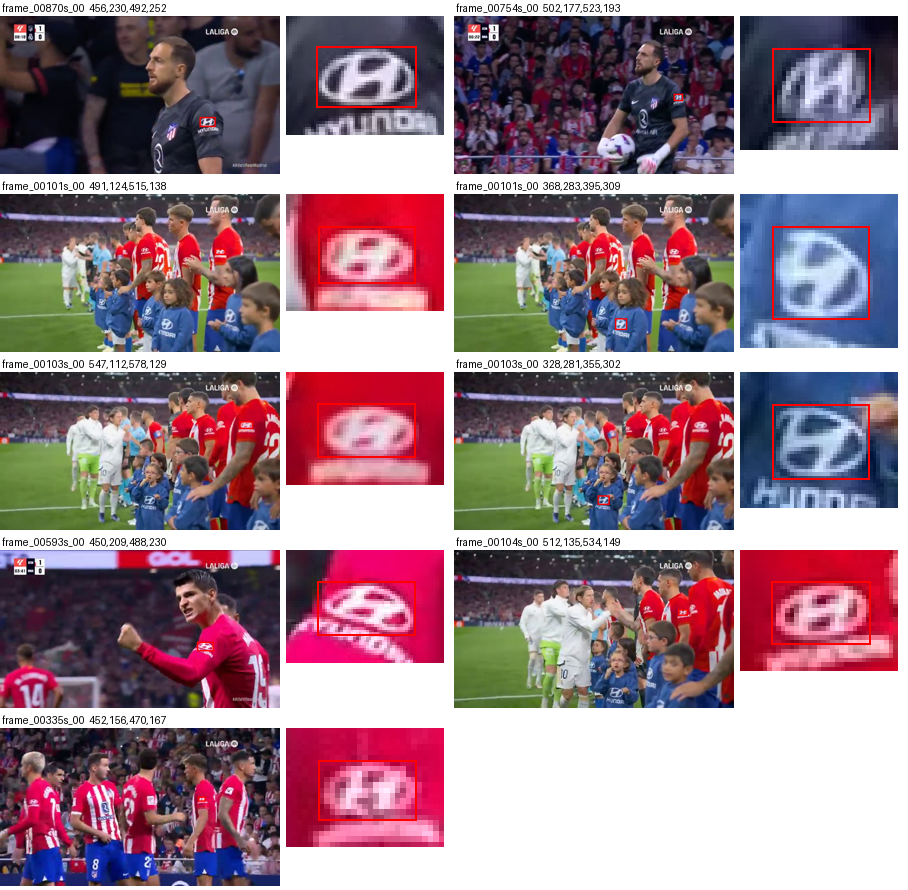


nike: 5 example(s)


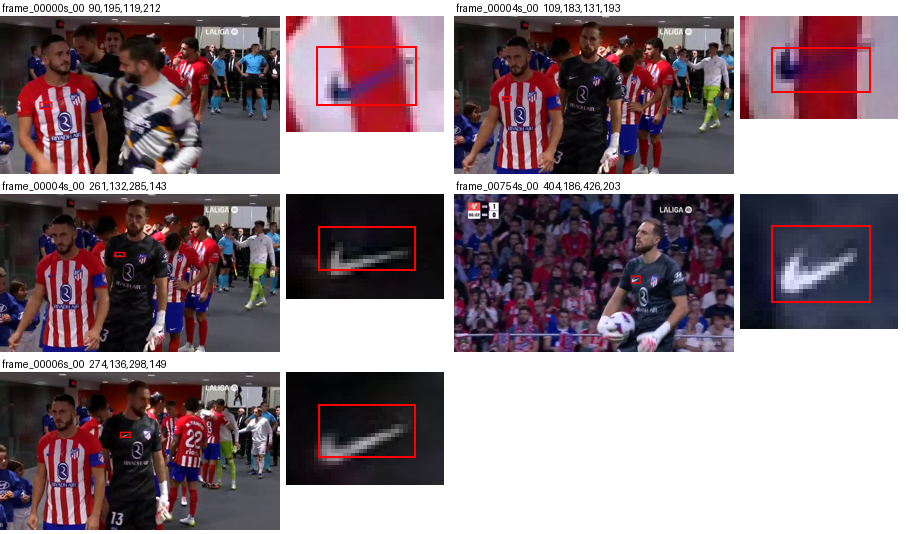


riyadh_air: 5 example(s)


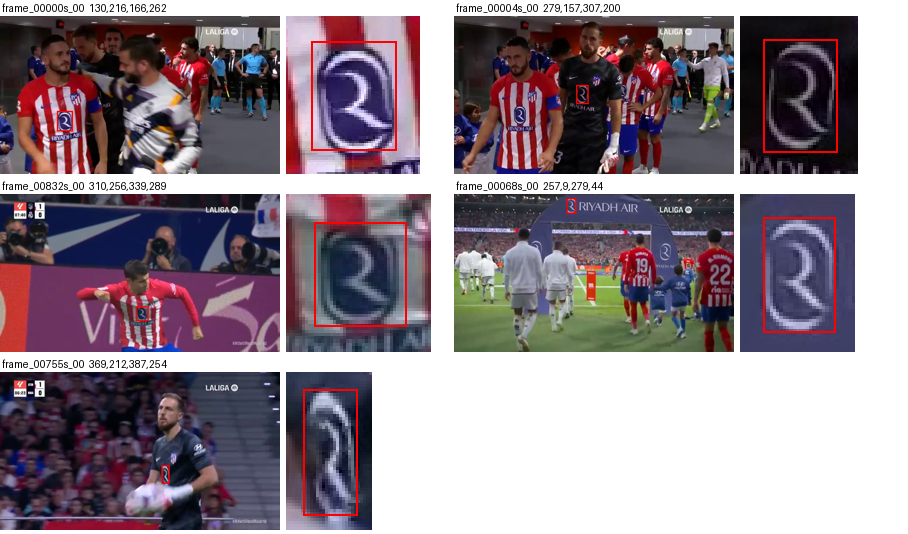


negative: 17 example(s)


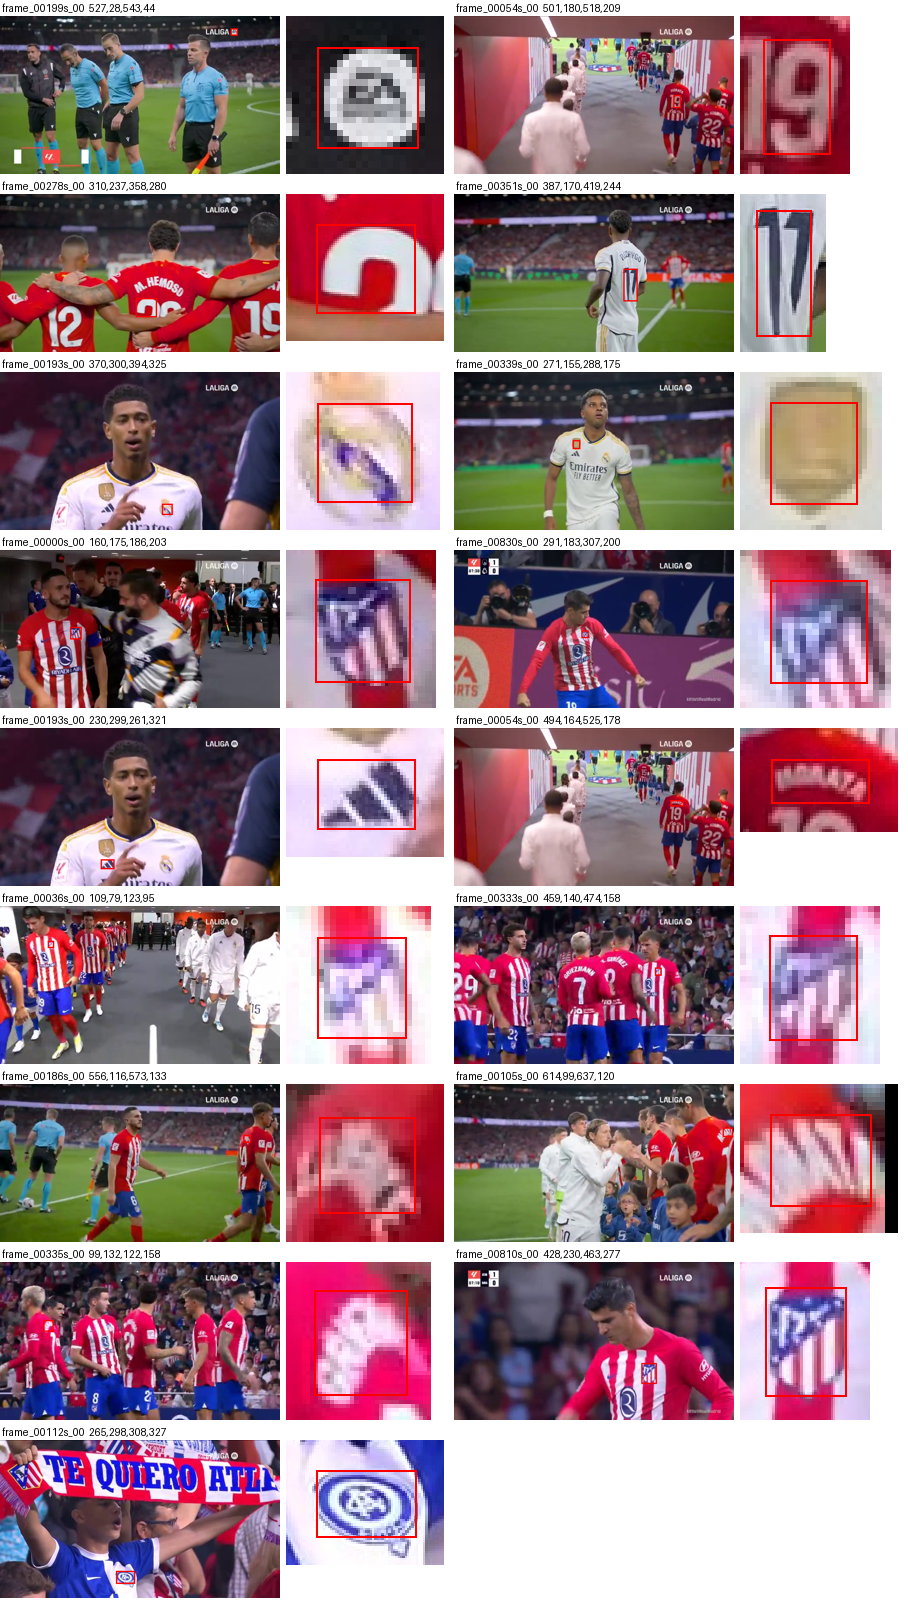

In [76]:
#@title 5. Check examples.txt and preview every example (red box = what it learns from)
from PIL import Image, ImageDraw
from IPython.display import display

def read_examples():
    examples, errors, warnings = [], [], []
    # CLASSES list is already lowercased with underscores from step 1
    valid_classes = set(CLASSES)

    for n, raw in enumerate(open(EXAMPLES_TXT, encoding="utf-8"), 1):
        line = raw.split("#", 1)[0].strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) < 3:
            errors.append(f"line {n}: expected 'brand frame x1,y1,x2,y2', got: {raw.strip()}"); continue

        # Use right-to-left parsing to support brands with spaces
        box = parts[-1]
        frame = parts[-2]
        brand = "_".join(parts[:-2]).lower().replace(' ', '_')

        if brand != "negative" and brand not in valid_classes:
            errors.append(f"line {n}: brand '{brand}' is not in CLASSES (normalized classes: {valid_classes}) or use 'negative'"); continue
        stem = Path(frame).stem
        if stem not in FRAME_FILES:
            errors.append(f"line {n}: frame '{frame}' not found in frames/"); continue
        try:
            x1, y1, x2, y2 = (float(v) for v in box.split(","))
        except ValueError:
            errors.append(f"line {n}: box must be x1,y1,x2,y2 numbers, got '{box}'"); continue
        W, H = Image.open(FRAME_FILES[stem]).size
        if not (0 <= x1 < x2 <= W and 0 <= y1 < y2 <= H):
            errors.append(f"line {n}: box {box} is not inside the {W}x{H} frame (need x1<x2, y1<y2)"); continue
        if min(x2 - x1, y2 - y1) < 8:
            warnings.append(f"line {n}: box {box} is very small ({x2-x1:.0f}x{y2-y1:.0f} px) - fine if the logo really is that small")
        examples.append((brand, stem, (x1, y1, x2, y2)))
    return examples, errors, warnings

def preview_examples(examples):
    for brand in [b for b in CLASSES if any(e[0] == b for e in examples)] + ["negative"]:
        rows = [e for e in examples if e[0] == brand]
        if not rows:
            continue
        TW, TH, Z = 280, 158, 158
        sheet = Image.new("RGB", (2 * (TW + Z + 16), ((len(rows) + 1) // 2) * (TH + 20)), "white"); d = ImageDraw.Draw(sheet)
        for i, (_, stem, (x1, y1, x2, y2)) in enumerate(rows):
            im = Image.open(FRAME_FILES[stem]).convert("RGB")
            th = im.copy(); ImageDraw.Draw(th).rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=max(2, im.width // 200)); th.thumbnail((TW, TH))
            m = max(4, (x2 - x1) * 0.3); cx0, cy0 = int(x1 - m), int(y1 - m)
            z = im.crop((cx0, cy0, int(x2 + m), int(y2 + m)))
            s = min(Z / z.width, Z / z.height); z = z.resize((max(1, int(z.width * s)), max(1, int(z.height * s))), Image.NEAREST)
            ImageDraw.Draw(z).rectangle([(x1 - cx0) * s, (y1 - cy0) * s, (x2 - cx0) * s, (y2 - cy0) * s], outline=(255, 0, 0), width=2)
            x, y = (i % 2) * (TW + Z + 16), (i // 2) * (TH + 20)
            d.text((x + 2, y + 2), f"{stem}  {int(x1)},{int(y1)},{int(x2)},{int(y2)}", fill=(0, 0, 0))
            sheet.paste(th, (x, y + 16)); sheet.paste(z, (x + TW + 6, y + 16))
        print(f"\n{brand}: {len(rows)} example(s)")
        display(sheet)

EXAMPLES, errs, warns = read_examples()
for w in warns: print("warning:", w)
if errs:
    print("\n".join("ERROR: " + e for e in errs))
    raise SystemExit("Fix examples.txt (see errors above), re-upload it, and run this cell again.")

counts = {b: sum(e[0] == b for e in EXAMPLES) for b in CLASSES + ["negative"]}
print("examples per brand:", {b: n for b, n in counts.items() if n})
print("brands with no examples (will not be detected):", [b for b in CLASSES if not counts[b]])
preview_examples(EXAMPLES)

In [77]:
#@title 6. Load the OWLv2 model and learn the examples
import time, csv
import torchvision
import torch.nn.functional as F
from transformers import Owlv2Processor, Owlv2ForObjectDetection

Image.MAX_IMAGE_PIXELS = None
MAX_SIDE = 1600       # bigger frames are shrunk to this (labels are fractions of the size, so they stay valid)
OVERLAP = 0.25        # tile overlap
CONTAIN = 0.6         # a box >60% inside a bigger box of the same brand is a logo part -> dropped
SAVE_FLOOR = 0.80     # candidates at or above this are saved, so cutoffs can be lowered to here later
MARGIN = 0.0          # a box must beat its best negative match by this much
DEV = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

MODEL_NAME = "google/owlv2-base-patch16-ensemble"
proc = Owlv2Processor.from_pretrained(MODEL_NAME)
model = Owlv2ForObjectDetection.from_pretrained(MODEL_NAME).to(DEV).eval()
print("model loaded on", DEV)

def load(path):
    img = Image.open(path).convert("RGB")
    if max(img.size) > MAX_SIDE:
        img.thumbnail((MAX_SIDE, MAX_SIDE))
    return img

@torch.no_grad()
def embed_batch(imgs):
    # OWL proposals for a batch of images: unit-length embeddings, cxcywh boxes (0-1 of the padded square)
    pv = proc(images=imgs, return_tensors="pt")["pixel_values"].to(DEV)
    fmap = model.image_embedder(pixel_values=pv)[0]
    b, h, w, d = fmap.shape
    feats = fmap.reshape(b, h * w, d)
    _, cls = model.class_predictor(feats)
    boxes = model.box_predictor(feats, fmap)
    return F.normalize(cls, dim=-1), boxes.cpu()

def to_pixels(boxes, w, h):
    b = torchvision.ops.box_convert(boxes, "cxcywh", "xyxy") * max(w, h)
    b[:, 0::2] = b[:, 0::2].clamp(0, w); b[:, 1::2] = b[:, 1::2].clamp(0, h)
    return b

def tile_size(W, H):
    return W / (TILES - (TILES - 1) * OVERLAP), H / (TILES - (TILES - 1) * OVERLAP)

def tile_windows(W, H):
    # overlapping TILES x TILES windows that together cover the whole frame
    if TILES <= 1:
        return []
    tw, th = tile_size(W, H); sx, sy = tw * (1 - OVERLAP), th * (1 - OVERLAP)
    return [(round(i * sx), round(j * sy), min(W, round(i * sx + tw)), min(H, round(j * sy + th)))
            for j in range(TILES) for i in range(TILES)]

def proposals(img):
    # all OWL boxes from the whole frame + tiles (one GPU batch), in frame pixels, with embeddings
    W, H = img.size
    wins = [None] + tile_windows(W, H)
    crops = [img if w is None else img.crop(w) for w in wins]
    cls, boxes = embed_batch(crops)
    all_e, all_b = [], []
    for k, (win, crop) in enumerate(zip(wins, crops)):
        cw, ch = crop.size
        b, e = to_pixels(boxes[k], cw, ch), cls[k]
        if win is not None:  # drop boxes cut by an inner tile edge (a neighbour tile / the full frame sees them whole)
            x0, y0, x1, y1 = win; E = 2
            cut = ((b[:, 0] <= E) & (x0 > 0)) | ((b[:, 2] >= cw - E) & (x1 < W)) | \
                  ((b[:, 1] <= E) & (y0 > 0)) | ((b[:, 3] >= ch - E) & (y1 < H))
            b, e = b[~cut] + torch.tensor([x0, y0, x0, y0], dtype=b.dtype), e[~cut.to(e.device)]
        all_b.append(b); all_e.append(e)
    return torch.cat(all_e), torch.cat(all_b)

def best_overlap_embedding(img, target):
    cls, boxes = embed_batch([img])
    iou = torchvision.ops.box_iou(to_pixels(boxes[0], *img.size), target)[:, 0]
    i = int(iou.argmax())
    return cls[0][i], float(iou[i])

def example_embeddings(stem, box):
    # an example is learned from the FULL frame at its real size (+ a tile-sized window, matching the tile scale)
    path = FRAME_FILES[stem]
    with Image.open(path) as orig:
        scale = load(path).width / orig.width
    img = load(path)
    target = torch.tensor([[v * scale for v in box]])
    embs, overlaps = [], []
    e, ov = best_overlap_embedding(img, target); embs.append(e); overlaps.append(ov)
    if TILES > 1:
        W, H = img.size; tw, th = tile_size(W, H)
        cx, cy = float(target[0, 0] + target[0, 2]) / 2, float(target[0, 1] + target[0, 3]) / 2
        x0 = round(min(max(cx - tw / 2, 0), W - tw)); y0 = round(min(max(cy - th / 2, 0), H - th))
        win = img.crop((x0, y0, round(x0 + tw), round(y0 + th)))
        e, ov = best_overlap_embedding(win, target - torch.tensor([[x0, y0, x0, y0]]))
        embs.append(e); overlaps.append(ov)
    return embs, min(overlaps)

t0 = time.time()
BRAND_EMB, neg_list = {}, []
for brand, stem, box in EXAMPLES:
    embs, ov = example_embeddings(stem, box)
    if ov < 0.3:
        print(f"warning: {brand} example in {stem} {box}: OWL found no box matching it well (overlap {ov:.2f}) - check the box")
    (neg_list if brand == "negative" else BRAND_EMB.setdefault(brand, [])).extend(embs)
BRAND_EMB = {b: torch.stack(v) for b, v in BRAND_EMB.items()}
NEG_EMB = torch.stack(neg_list) if neg_list else None
BRAND_NAMES = list(BRAND_EMB)
print(f"learned {len(EXAMPLES)} examples in {time.time() - t0:.0f}s - detecting: {BRAND_NAMES}")

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

model loaded on cuda
learned 36 examples in 34s - detecting: ['riyadh_air', 'hyundai', 'nike']


In [78]:
#@title 7. Detect logos in all frames (continues where it stopped if re-run)
PALETTE = [(0, 255, 0), (255, 64, 64), (64, 160, 255), (255, 200, 0), (255, 0, 255), (0, 255, 255), (255, 128, 0), (160, 96, 255)]

def score_frame(img):
    # every box goes to the brand it matches best; kept if it beats all negatives
    e, b = proposals(img)
    sims = torch.stack([(e @ BRAND_EMB[n].T).max(dim=1).values for n in BRAND_NAMES], dim=1).cpu()
    best, idx = sims.max(dim=1)
    neg = (e @ NEG_EMB.T).max(dim=1).values.cpu() if NEG_EMB is not None else torch.full_like(best, -1.0)
    wh = b[:, 2:] - b[:, :2]
    ok = (wh[:, 0] > 6) & (wh[:, 1] > 6) & (best > neg + MARGIN) & (best >= SAVE_FLOOR)
    b, best, idx = b[ok], best[ok], idx[ok]
    keep = torchvision.ops.nms(b, best, 0.3)
    return [(BRAND_NAMES[int(idx[i])], float(best[i]), *[float(v) for v in b[i]]) for i in keep]

def cutoff(brand):
    return CUTOFFS.get(brand, DEFAULT_CUTOFF)

def kept_boxes(cands):
    # apply per-brand cutoffs, then drop logo parts (box mostly inside a bigger box of the same brand)
    kept = []
    for brand in {c[0] for c in cands}:
        rows = sorted((c for c in cands if c[0] == brand and c[1] >= cutoff(brand)),
                      key=lambda c: (c[4] - c[2]) * (c[5] - c[3]), reverse=True)
        mine = []
        for c in rows:
            area = (c[4] - c[2]) * (c[5] - c[3])
            if not any(max(0, min(c[4], k[4]) - max(c[2], k[2])) * max(0, min(c[5], k[5]) - max(c[3], k[3])) > CONTAIN * area for k in mine):
                mine.append(c)
        kept += mine
    return sorted(kept, key=lambda c: -c[1])

def read_candidates(stem):
    f = OUT / "candidates" / f"{stem}.txt"
    return [(p[0], *map(float, p[1:])) for p in (l.split() for l in f.read_text().splitlines()) if p] if f.exists() else []

def write_frame(stem, img, cands, annotate=True):
    W, H = img.size
    boxes = kept_boxes(cands)
    lines = [f"{CLASSES.index(br)} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}\n" for br, sc, x1, y1, x2, y2 in boxes]
    (OUT / "labels" / f"{stem}.txt").write_text("".join(lines))
    if annotate:
        im = img.copy(); d = ImageDraw.Draw(im); lw = max(2, max(W, H) // 300)
        for br, sc, x1, y1, x2, y2 in boxes:
            col = PALETTE[CLASSES.index(br) % len(PALETTE)]
            d.rectangle([x1, y1, x2, y2], outline=col, width=lw); d.text((x1 + 2, max(0, y1 - 12)), f"{br} {sc:.2f}", fill=col)
        im.save(OUT / "annotated" / f"{stem}.jpg", quality=90)
    return boxes

def run(resume=True):
    stems = [s for s in FRAME_FILES if not ONLY_FRAMES or s in {Path(f).stem for f in ONLY_FRAMES}]
    todo = [s for s in stems if not (resume and (OUT / "candidates" / f"{s}.txt").exists())]
    print(f"{len(stems)} frames, {len(stems) - len(todo)} already done, {len(todo)} to go")
    t0 = time.time()
    for i, stem in enumerate(todo, 1):
        img = load(FRAME_FILES[stem])
        cands = score_frame(img)
        boxes = write_frame(stem, img, cands)
        # candidates are written last: a frame counts as done only when everything for it is saved
        (OUT / "candidates" / f"{stem}.txt").write_text("".join(f"{c[0]} {c[1]:.4f} {c[2]:.1f} {c[3]:.1f} {c[4]:.1f} {c[5]:.1f}\n" for c in cands))
        if i == 1 or i % 25 == 0 or i == len(todo):
            el = time.time() - t0
            print(f"{i}/{len(todo)} frames  {el:.0f}s  (~{el / i * (len(todo) - i) / 60:.1f} min left)  last: {stem} -> "
                  + (", ".join(f"{b[0]} {b[1]:.2f}" for b in boxes) or "no logos"))
    summary()

def summary(save=True):
    rows = []
    done = [s for s in FRAME_FILES if (OUT / "candidates" / f"{s}.txt").exists()]
    for k, brand in enumerate(CLASSES):
        frames = boxes = 0; area = 0.0
        for s in done:
            mine = [l.split() for l in (OUT / "labels" / f"{s}.txt").read_text().splitlines() if l.split() and int(l.split()[0]) == k]
            frames += bool(mine); boxes += len(mine); area += sum(float(m[3]) * float(m[4]) for m in mine)
        rows.append({"class_id": k, "brand": brand, "cutoff": cutoff(brand), "frames_with_logo": frames,
                     "boxes": boxes, "avg_box_area_pct": round(100 * area / boxes, 3) if boxes else 0})
    print(f"\n{len(done)} frames labeled:")
    for r in rows:
        print(f"  {r['class_id']} {r['brand']:<12} cutoff {r['cutoff']:.2f}   frames {r['frames_with_logo']:>4}   boxes {r['boxes']:>4}   avg box {r['avg_box_area_pct']}% of frame")
    if save:
        with open(OUT / "summary.csv", "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)

run()

100 frames, 38 already done, 62 to go
1/62 frames  2s  (~2.4 min left)  last: frame_00036s_00 -> riyadh_air 0.94
25/62 frames  61s  (~1.5 min left)  last: frame_00830s_00 -> riyadh_air 0.97
50/62 frames  121s  (~0.5 min left)  last: frame_05120s_00 -> no logos
62/62 frames  150s  (~0.0 min left)  last: frame_06597s_00 -> no logos

100 frames labeled:
  0 adidas       cutoff 0.93   frames    3   boxes    3   avg box 0.199% of frame
  1 emirates     cutoff 0.93   frames   35   boxes  231   avg box 4.776% of frame
  2 hyundai      cutoff 0.93   frames   18   boxes   31   avg box 0.252% of frame
  3 nike         cutoff 0.93   frames    7   boxes   10   avg box 0.107% of frame
  4 ria_money_transfer cutoff 0.93   frames    4   boxes    6   avg box 0.212% of frame
  5 riyadh_air   cutoff 0.93   frames   45   boxes   92   avg box 1.273% of frame


In [ ]:
#@title 8. Check the boxes - every box zoomed in, sorted by score (lowest scores are the ones to doubt)
def show_boxes(brand=None, max_boxes=96, lowest_first=False):
    items = []
    for stem in FRAME_FILES:
        for c in kept_boxes(read_candidates(stem)):
            if brand is None or c[0] == brand:
                items.append((c[1], c[0], stem, *c[2:]))
    items.sort(reverse=not lowest_first)
    print(f"{len(items)} boxes" + (f" for {brand}" if brand else "") + (f" (showing {max_boxes})" if len(items) > max_boxes else ""))
    items = items[:max_boxes]
    if not items:
        return
    Z, COLS = 150, 8
    sheet = Image.new("RGB", (COLS * Z, ((len(items) + COLS - 1) // COLS) * (Z + 26)), "white"); d = ImageDraw.Draw(sheet)
    for i, (sc, br, stem, x1, y1, x2, y2) in enumerate(items):
        im = load(FRAME_FILES[stem]); m = max(x2 - x1, y2 - y1) * 1.2
        z = im.crop((int(x1 - m), int(y1 - m), int(x2 + m), int(y2 + m)))
        ImageDraw.Draw(z).rectangle([x1 - int(x1 - m), y1 - int(y1 - m), x2 - int(x1 - m), y2 - int(y1 - m)],
                                    outline=PALETTE[CLASSES.index(br) % len(PALETTE)], width=2)
        x, y = (i % COLS) * Z, (i // COLS) * (Z + 26)
        sheet.paste(z.resize((Z, Z)), (x, y + 26))
        d.text((x + 2, y + 1), f"{br} {sc:.3f}", fill=(0, 0, 0)); d.text((x + 2, y + 13), stem, fill=(90, 90, 90))
    display(sheet)

for b in BRAND_NAMES:
    show_boxes(b)

In [80]:
# 9. Change a brand's cutoff (takes seconds - no model run). Lower = more logos but more mistakes.
#    Candidates were saved down to 0.80, so a cutoff can't go below that without re-running step 7 with resume=False.
def set_cutoff(brand, value, annotate=True):
    CUTOFFS[brand] = value
    for stem in FRAME_FILES:
        if (OUT / "candidates" / f"{stem}.txt").exists():
            write_frame(stem, load(FRAME_FILES[stem]), read_candidates(stem), annotate=annotate)
    summary()
    show_boxes(brand, lowest_first=True, max_boxes=48)

# set_cutoff("riyadh_air", 0.92)

In [84]:
# 10. Export a YOLO dataset (frames that have at least one logo + their labels + data.yaml)
def export_yolo(include_empty=False):
    ds = OUT / "yolo_dataset"
    (ds / "images").mkdir(parents=True, exist_ok=True); (ds / "labels").mkdir(parents=True, exist_ok=True)
    n = 0
    for stem, path in FRAME_FILES.items():
        lab = OUT / "labels" / f"{stem}.txt"
        if lab.exists() and (include_empty or lab.stat().st_size > 0):
            shutil.copy(path, ds / "images" / path.name); shutil.copy(lab, ds / "labels" / lab.name); n += 1
    names = "\n".join(f"  {i}: {c}" for i, c in enumerate(CLASSES))
    (ds / "data.yaml").write_text(f"path: {ds}\ntrain: images\nval: images   # split by time before training\nnames:\n{names}\n")
    summary()
    print(f"\nexported {n} frames -> {ds}")

export_yolo()


100 frames labeled:
  0 adidas       cutoff 0.93   frames    3   boxes    3   avg box 0.199% of frame
  1 emirates     cutoff 0.93   frames   35   boxes  231   avg box 4.776% of frame
  2 hyundai      cutoff 0.93   frames   18   boxes   31   avg box 0.252% of frame
  3 nike         cutoff 0.93   frames    7   boxes   10   avg box 0.107% of frame
  4 ria_money_transfer cutoff 0.93   frames    4   boxes    6   avg box 0.212% of frame
  5 riyadh_air   cutoff 0.93   frames   45   boxes   92   avg box 1.273% of frame

exported 61 frames -> /content/drive/MyDrive/matches/real_madrid_vs_atletico_madrid/owl_output/yolo_dataset


### Notes
- **Pipeline order:** upload match MP4 → step 3b builds `close_ups.zip` → step 3c feeds close-ups into OWL → steps 5–10 label/export.
- **Already have frames?** Set `VIDEO_PATH = None` (or leave extract skipped) and keep `close_ups/`, `frames/`, or `close_ups.zip` in `MATCH_DIR`.
- **Changed `examples.txt` or `TILES`?** Re-run steps 5-6, then run step 7 as `run(resume=False)` so every frame is redone with the new examples.
- **Bad boxes on one kind of thing** (a crest, the league badge, a sponsor that isn't in `CLASSES`)? Add a few `negative` lines for it and re-run as above.
- **Missing logos?** Add more examples of that brand from frames where it was missed (different kit, angle, blur), or lower its cutoff in step 9.
- Before training, split train/val **by time** (e.g. first 80% of the match / last 20%), not randomly - neighbouring frames are near-duplicates.